# Knowledge Distillation — FitNets Experiment

**Setup:** CIFAR-10 · ResNet-34 teacher · ResNet-18 student

Mirrors the Vanilla KD / Attention Transfer notebooks' structure (Drive persistence, resumable
checkpoints, smoke tests). Teacher and baseline are **loaded from Drive, not trained here** —
only the FitNets student is trained.

**FitNets is a two-stage algorithm** (Romero et al., 2015), structurally different from vanilla KD
and AT — it isn't a single combined loss:

- **Stage 1 — Hint training.** The student's early layers (up to a chosen "guided" layer,
  `layer2` here) are trained to regress a single intermediate feature map from the teacher's
  matching "hint" layer, via a small learned regressor. This only touches the student's front
  layers; `layer3`, `layer4`, and `fc` are untouched and stay randomly initialized.
- **Stage 2 — KD-style training.** The *whole* student network is then trained with the same
  CE + KL loss as vanilla KD, starting from the Stage-1 weights instead of random init.

Total epoch budget is split as **5 (hint) + 30 (KD) = 35 epochs**, to match the total training
budget used for the vanilla KD and AT students, so the three-way comparison stays fair.

Final weights are saved as `fitnets_resnet18.pth`.

In [1]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import os
import sys
import time
import json
import random
import numpy as np
import torch

PROJECT_DIR = Path("/content/drive/MyDrive/kd_experiments")
DATA_DIR = PROJECT_DIR / "data"
WEIGHTS_DIR = PROJECT_DIR / "weights"
CHECKPOINTS_DIR = PROJECT_DIR / "checkpoints"
RESULTS_DIR = PROJECT_DIR / "results"
LOGS_DIR = PROJECT_DIR / "logs"

for directory in [
    PROJECT_DIR, DATA_DIR, WEIGHTS_DIR, CHECKPOINTS_DIR, RESULTS_DIR, LOGS_DIR
]:
    directory.mkdir(parents=True, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Project:", PROJECT_DIR)
print("Data:   ", DATA_DIR)
print("Weights:", WEIGHTS_DIR)
print("Device: ", device)

if torch.cuda.is_available():
    print("GPU:    ", torch.cuda.get_device_name(0))
    print("CUDA:   ", torch.version.cuda)

Mounted at /content/drive
Project: /content/drive/MyDrive/kd_experiments
Data:    /content/drive/MyDrive/kd_experiments/data
Weights: /content/drive/MyDrive/kd_experiments/weights
Device:  cuda
GPU:     Tesla T4
CUDA:    12.8


In [3]:
!ls /content/drive/MyDrive/

 12.pdf
'24220 copy.jpg'
 AOA.gdoc
'assignment (1).md.gdoc'
 assignment.md.gdoc
 car_classifier_resnet18.pth
 chapter_1_concept_of_data_structures.gdoc
'Chapter 2 - Data Communication Fundamentals - DC.gdoc'
'chem new_merged_compressed.pdf'
'citizenship (1).pdf'
 Classroom
'Colab Notebooks'
'DC Microsyllabus - BCT.gdoc'
'Drug Efficacy: T-Test and Recommendation.gsheet'
'Elective II BCT III_II Batch 2080 (Responses).xlsx'
 ELECTRICAL_CIRCUITS_AND_MACHINES.pdf.gdoc
'First Game (DEBUG) 2024-12-28 18-55-16 (1).mp4'
'First Game (DEBUG) 2024-12-28 18-55-16.mp4'
'Gemini Gems'
 Heart_Disease_Prediction.gsheet
'Horror3D (1).exe'
 Horror3D.exe
 image_2026-02-16_235444623.png
 IMG_20230604_132037.jpg
 IMG_20230627_202734.jpg
'IMG_20231013_082150 (1).jpg'
 inbound231228653428642806.pdf
 inbound543900772998129970.jpg
'IRON FIST_2025-01-19_14-39-29.mp4'
 kd_experiments
 lakhey
 lms.pptx
'New Doc 11-06-2020 19.48.pdf'
'Non-Disclosure Agreement for students of Fusemachines AI School.pdf'
'Practice Set

In [4]:
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader

import torchvision
import torchvision.transforms as transforms

from tqdm.auto import tqdm
import matplotlib.pyplot as plt

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)

PyTorch: 2.11.0+cu128
Torchvision: 0.26.0+cu128


In [5]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.benchmark = True

print("Seed:", SEED)
print("cuDNN benchmark:", torch.backends.cudnn.benchmark)

Seed: 42
cuDNN benchmark: True


In [6]:
CIFAR10_ROOT = str(DATA_DIR)

# CIFAR-10 normalization (same as vanilla KD / AT notebooks)
mean = (0.4914, 0.4822, 0.4465)
std = (0.2470, 0.2435, 0.2616)

train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

train_dataset = torchvision.datasets.CIFAR10(
    root=CIFAR10_ROOT,
    train=True,
    download=True,
    transform=train_transform,
)

test_dataset = torchvision.datasets.CIFAR10(
    root=CIFAR10_ROOT,
    train=False,
    download=True,
    transform=test_transform,
)

print("Train samples:", len(train_dataset))
print("Test samples: ", len(test_dataset))
print("Dataset root: ", CIFAR10_ROOT)

Train samples: 50000
Test samples:  10000
Dataset root:  /content/drive/MyDrive/kd_experiments/data


In [7]:
BATCH_SIZE = 128
NUM_WORKERS = 2

pin_memory = torch.cuda.is_available()

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=pin_memory,
    persistent_workers=(NUM_WORKERS > 0),
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=pin_memory,
    persistent_workers=(NUM_WORKERS > 0),
)

print("Batch size:", BATCH_SIZE)
print("Train batches:", len(train_loader))
print("Test batches:", len(test_loader))

Batch size: 128
Train batches: 391
Test batches: 79


## Models

In [8]:
from torchvision.models.resnet import ResNet, BasicBlock

def cifar_resnet18(num_classes=10):
    model = ResNet(
        block=BasicBlock,
        layers=[2, 2, 2, 2],
        num_classes=num_classes,
    )

    model.conv1 = nn.Conv2d(
        3, 64,
        kernel_size=3,
        stride=1,
        padding=1,
        bias=False,
    )
    model.maxpool = nn.Identity()

    return model


def cifar_resnet34(num_classes=10):
    model = ResNet(
        block=BasicBlock,
        layers=[3, 4, 6, 3],
        num_classes=num_classes,
    )

    model.conv1 = nn.Conv2d(
        3, 64,
        kernel_size=3,
        stride=1,
        padding=1,
        bias=False,
    )
    model.maxpool = nn.Identity()

    return model

In [9]:
NUM_EPOCHS_KD = 30      # Stage 2 (KD-style) epochs
HINT_EPOCHS = 5         # Stage 1 (hint pretraining) epochs
# 5 + 30 = 35 total, matching the epoch budget used for vanilla KD / AT students

SMOKE_TEST_HINT_EPOCHS = 2
SMOKE_TEST_KD_EPOCHS = 2

LEARNING_RATE = 0.1     # Stage 2 optimizer
MOMENTUM = 0.9
WEIGHT_DECAY = 5e-4

HINT_LEARNING_RATE = 0.01  # Stage 1 optimizer (feature regression is more sensitive; smaller LR keeps it stable)

# Stage 2 uses the same KD formula as vanilla KD, for a fair comparison
TEMPERATURE = 4.0
ALPHA = 0.9

HINT_LAYER = "layer2"   # guided/hint layer -- roughly the middle of the network

WEIGHT_FILES = {
    "teacher": "teacher_resnet34.pth",
    "baseline": "baseline_resnet18.pth",
    "fitnets": "fitnets_resnet18.pth",
}

CHECKPOINT_FILES = {
    "fitnets_hint": "fitnets_hint_checkpoint.pth",
    "fitnets_kd": "fitnets_kd_checkpoint.pth",
}

SMOKE_HINT_CHECKPOINT_FILE = "fitnets_hint_smoke_checkpoint.pth"
SMOKE_KD_CHECKPOINT_FILE = "fitnets_kd_smoke_checkpoint.pth"
SMOKE_KD_WEIGHT_FILE = "fitnets_resnet18_smoke.pth"

print(f"Stage 1 (hint) epochs: {HINT_EPOCHS}")
print(f"Stage 2 (KD) epochs:   {NUM_EPOCHS_KD}")
print(f"Hint layer: {HINT_LAYER}")

Stage 1 (hint) epochs: 5
Stage 2 (KD) epochs:   30
Hint layer: layer2


In [10]:
def save_weights(model, filename):
    path = WEIGHTS_DIR / filename
    torch.save(model.state_dict(), path)
    print(f"Saved weights: {path}")
    return path


def save_training_checkpoint(
    model,
    optimizer,
    scheduler,
    epoch,
    best_accuracy,
    history,
    filename,
    extra_state=None,
):
    checkpoint = {
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict() if optimizer else None,
        "scheduler_state_dict": scheduler.state_dict() if scheduler else None,
        "best_accuracy": best_accuracy,
        "history": history,
    }
    if extra_state is not None:
        checkpoint["extra_state"] = extra_state

    path = CHECKPOINTS_DIR / filename
    torch.save(checkpoint, path)
    return path


def load_training_checkpoint(
    model,
    optimizer=None,
    scheduler=None,
    filename=None,
):
    path = CHECKPOINTS_DIR / filename

    checkpoint = torch.load(path, map_location=device)

    model.load_state_dict(checkpoint["model_state_dict"])

    if optimizer is not None and checkpoint["optimizer_state_dict"] is not None:
        optimizer.load_state_dict(checkpoint["optimizer_state_dict"])

    if scheduler is not None and checkpoint["scheduler_state_dict"] is not None:
        scheduler.load_state_dict(checkpoint["scheduler_state_dict"])

    print(f"Loaded checkpoint: {path}")
    print(f"Last completed epoch: {checkpoint['epoch']}")

    return checkpoint


def load_weights(model, filename):
    path = WEIGHTS_DIR / filename
    model.load_state_dict(torch.load(path, map_location=device))
    model.to(device)
    return model

In [11]:
@torch.no_grad()
def evaluate(model, loader):
    model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    criterion = nn.CrossEntropyLoss()

    for images, targets in loader:
        images = images.to(device, non_blocking=True)
        targets = targets.to(device, non_blocking=True)

        with torch.amp.autocast("cuda", enabled=torch.cuda.is_available()):
            logits = model(images)
            loss = criterion(logits, targets)

        total_loss += loss.item() * targets.size(0)
        correct += (logits.argmax(dim=1) == targets).sum().item()
        total += targets.size(0)

    return total_loss / total, 100.0 * correct / total

## Teacher & Baseline — loaded from Drive, not trained here

In [12]:
teacher = load_weights(cifar_resnet34(), WEIGHT_FILES["teacher"])
teacher.eval()
for param in teacher.parameters():
    param.requires_grad = False

baseline = load_weights(cifar_resnet18(), WEIGHT_FILES["baseline"])
baseline.eval()
for param in baseline.parameters():
    param.requires_grad = False

print("Teacher parameters:", sum(p.numel() for p in teacher.parameters()))
print("Baseline parameters:", sum(p.numel() for p in baseline.parameters()))

teacher_loss, teacher_acc = evaluate(teacher, test_loader)
baseline_loss, baseline_acc = evaluate(baseline, test_loader)

print(f"Teacher test accuracy:  {teacher_acc:.2f}%")
print(f"Baseline test accuracy: {baseline_acc:.2f}%")

Teacher parameters: 21282122
Baseline parameters: 11173962
Teacher test accuracy:  94.48%
Baseline test accuracy: 93.77%


## Hint layer forward + regressor

Instead of hooking all 4 stages like AT, FitNets only needs a **partial forward** through
each network up to the single guided/hint layer -- so we skip computing (and storing gradients
for) anything past that layer during Stage 1.

In [13]:
def forward_to_hint_layer(model, x, hint_layer=HINT_LAYER):
    """Manual partial forward through a CIFAR ResNet, stopping at `hint_layer`."""
    x = model.conv1(x)
    x = model.bn1(x)
    x = model.relu(x)
    x = model.maxpool(x)

    x = model.layer1(x)
    if hint_layer == "layer1":
        return x

    x = model.layer2(x)
    if hint_layer == "layer2":
        return x

    x = model.layer3(x)
    if hint_layer == "layer3":
        return x

    x = model.layer4(x)
    return x


class Regressor(nn.Module):
    """Small learned adapter mapping the student's hint-layer features onto
    the teacher's. Even when channel counts already match (as they do here
    for CIFAR ResNet-18 vs ResNet-34 at every stage), a regressor is kept
    per the original FitNets recipe -- it gives Stage 1 a bit of learnable
    slack instead of forcing an exact identity match."""

    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.conv = nn.Conv2d(in_channels, out_channels, kernel_size=1, bias=False)
        self.bn = nn.BatchNorm2d(out_channels)

    def forward(self, x):
        return self.bn(self.conv(x))


def build_fitnets_student_and_regressor():
    student = cifar_resnet18().to(device)

    with torch.no_grad():
        probe = torch.zeros(1, 3, 32, 32, device=device)
        student_channels = forward_to_hint_layer(student, probe).shape[1]
        teacher_channels = forward_to_hint_layer(teacher, probe).shape[1]

    regressor = Regressor(student_channels, teacher_channels).to(device)
    return student, regressor

In [14]:
# Sanity check: confirm student/teacher hint-layer feature maps are
# spatially compatible (channel mismatch is fine -- that's what the
# regressor is for -- but H, W must match for the MSE to make sense).
_check_student, _check_regressor = build_fitnets_student_and_regressor()

sample_images, _ = next(iter(train_loader))
sample_images = sample_images.to(device)

with torch.no_grad():
    teacher_hint = forward_to_hint_layer(teacher, sample_images)
    student_hint = forward_to_hint_layer(_check_student, sample_images)
    student_hint_mapped = _check_regressor(student_hint)

print(f"Teacher hint shape:          {tuple(teacher_hint.shape)}")
print(f"Student hint shape (raw):    {tuple(student_hint.shape)}")
print(f"Student hint shape (mapped): {tuple(student_hint_mapped.shape)}")

status = "OK" if teacher_hint.shape[2:] == student_hint_mapped.shape[2:] else "MISMATCH"
print(f"Spatial compatibility: {status}")

del _check_student, _check_regressor, teacher_hint, student_hint, student_hint_mapped

Teacher hint shape:          (128, 128, 16, 16)
Student hint shape (raw):    (128, 128, 16, 16)
Student hint shape (mapped): (128, 128, 16, 16)
Spatial compatibility: OK


## Stage 1 — Hint training

Trains the student's layers up to `HINT_LAYER` (plus the regressor) to regress the teacher's
hint-layer activations. `layer3`, `layer4`, and `fc` never get a gradient here since the
forward pass stops before reaching them -- they stay at random init until Stage 2.

In [15]:
def train_fitnets_hint(
    teacher,
    student,
    regressor,
    epochs=HINT_EPOCHS,
    lr=HINT_LEARNING_RATE,
    resume=True,
    checkpoint_filename=None,
):
    checkpoint_filename = checkpoint_filename or CHECKPOINT_FILES["fitnets_hint"]

    teacher = teacher.to(device)
    student = student.to(device)
    regressor = regressor.to(device)
    teacher.eval()

    params = list(student.parameters()) + list(regressor.parameters())
    optimizer = optim.SGD(params, lr=lr, momentum=MOMENTUM, weight_decay=WEIGHT_DECAY)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

    scaler = torch.amp.GradScaler("cuda", enabled=torch.cuda.is_available())

    history = {"hint_loss": []}

    checkpoint_path = CHECKPOINTS_DIR / checkpoint_filename
    start_epoch = 0

    if resume and checkpoint_path.exists():
        checkpoint = torch.load(checkpoint_path, map_location=device)
        student.load_state_dict(checkpoint["model_state_dict"])
        regressor.load_state_dict(checkpoint["extra_state"]["regressor_state_dict"])
        optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
        scheduler.load_state_dict(checkpoint["scheduler_state_dict"])
        start_epoch = checkpoint["epoch"]
        history = checkpoint["history"]
        print(f"Resumed hint training from epoch {start_epoch}")

        if start_epoch >= epochs:
            print(f"Hint training already completed {start_epoch} epochs.")
            return student, regressor, history

    for epoch in range(start_epoch, epochs):
        student.train()
        regressor.train()

        running_loss = 0.0
        total = 0

        start_time = time.time()

        progress = tqdm(
            train_loader,
            desc=f"FitNets Hint | Epoch {epoch+1}/{epochs}",
            leave=False,
        )

        for images, targets in progress:
            images = images.to(device, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)

            with torch.no_grad():
                with torch.amp.autocast("cuda", enabled=torch.cuda.is_available()):
                    teacher_hint = forward_to_hint_layer(teacher, images).detach().float()

            with torch.amp.autocast("cuda", enabled=torch.cuda.is_available()):
                student_hint = forward_to_hint_layer(student, images)
                student_hint_mapped = regressor(student_hint.float())
                loss = F.mse_loss(student_hint_mapped, teacher_hint)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            batch_size = images.size(0)
            running_loss += loss.item() * batch_size
            total += batch_size

        scheduler.step()

        hint_loss_value = running_loss / total
        history["hint_loss"].append(hint_loss_value)

        elapsed = time.time() - start_time

        print(
            f"Epoch {epoch+1}/{epochs} | "
            f"Hint Loss: {hint_loss_value:.6f} | "
            f"Time: {elapsed/60:.2f} min"
        )

        save_training_checkpoint(
            student, optimizer, scheduler, epoch + 1, 0.0, history,
            checkpoint_filename,
            extra_state={"regressor_state_dict": regressor.state_dict()},
        )

    return student, regressor, history

## Stage 2 — KD-style training

Same CE + KL loss as vanilla KD, now applied to the whole student network, starting from the
Stage 1 hint-pretrained weights instead of random init.

In [16]:
def make_optimizer(model):
    return optim.SGD(
        model.parameters(),
        lr=LEARNING_RATE,
        momentum=MOMENTUM,
        weight_decay=WEIGHT_DECAY,
    )


def make_scheduler(optimizer, epochs):
    return optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=epochs,
    )


def vanilla_kd_loss(
    student_logits,
    teacher_logits,
    targets,
    temperature=TEMPERATURE,
    alpha=ALPHA,
):
    hard_loss = F.cross_entropy(student_logits, targets)

    student_log_probs = F.log_softmax(student_logits / temperature, dim=1)
    teacher_probs = F.softmax(teacher_logits / temperature, dim=1)

    soft_loss = F.kl_div(
        student_log_probs,
        teacher_probs,
        reduction="batchmean",
    ) * (temperature ** 2)

    total_loss = alpha * soft_loss + (1.0 - alpha) * hard_loss

    return total_loss, hard_loss.detach(), soft_loss.detach()

In [17]:
def train_fitnets_kd(
    teacher,
    student,
    epochs=NUM_EPOCHS_KD,
    resume=True,
    checkpoint_filename=None,
    weight_filename=None,
):
    checkpoint_filename = checkpoint_filename or CHECKPOINT_FILES["fitnets_kd"]
    weight_filename = weight_filename or WEIGHT_FILES["fitnets"]

    teacher = teacher.to(device)
    student = student.to(device)
    teacher.eval()

    optimizer = make_optimizer(student)
    scheduler = make_scheduler(optimizer, epochs)

    scaler = torch.amp.GradScaler("cuda", enabled=torch.cuda.is_available())

    history = {
        "train_loss": [],
        "hard_loss": [],
        "soft_loss": [],
        "train_accuracy": [],
        "test_loss": [],
        "test_accuracy": [],
    }

    checkpoint_path = CHECKPOINTS_DIR / checkpoint_filename
    start_epoch = 0
    best_accuracy = 0.0

    if resume and checkpoint_path.exists():
        checkpoint = load_training_checkpoint(
            student, optimizer, scheduler, checkpoint_filename,
        )
        start_epoch = checkpoint["epoch"]
        best_accuracy = checkpoint["best_accuracy"]
        history = checkpoint["history"]

        if start_epoch >= epochs:
            print(f"FitNets KD stage already completed {start_epoch} epochs.")
            return student, history

    for epoch in range(start_epoch, epochs):
        student.train()

        running_loss = 0.0
        running_hard = 0.0
        running_soft = 0.0
        correct = 0
        total = 0

        start_time = time.time()

        progress = tqdm(
            train_loader,
            desc=f"FitNets KD | Epoch {epoch+1}/{epochs}",
            leave=False,
        )

        for images, targets in progress:
            images = images.to(device, non_blocking=True)
            targets = targets.to(device, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)

            with torch.no_grad():
                with torch.amp.autocast("cuda", enabled=torch.cuda.is_available()):
                    teacher_logits = teacher(images)

            with torch.amp.autocast("cuda", enabled=torch.cuda.is_available()):
                student_logits = student(images)
                loss, hard_loss, soft_loss = vanilla_kd_loss(
                    student_logits, teacher_logits, targets,
                )

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            batch_size = targets.size(0)

            running_loss += loss.item() * batch_size
            running_hard += hard_loss.item() * batch_size
            running_soft += soft_loss.item() * batch_size

            correct += (student_logits.argmax(dim=1) == targets).sum().item()
            total += batch_size

        scheduler.step()

        train_loss = running_loss / total
        hard_loss_value = running_hard / total
        soft_loss_value = running_soft / total
        train_accuracy = 100.0 * correct / total

        test_loss, test_accuracy = evaluate(student, test_loader)

        history["train_loss"].append(train_loss)
        history["hard_loss"].append(hard_loss_value)
        history["soft_loss"].append(soft_loss_value)
        history["train_accuracy"].append(train_accuracy)
        history["test_loss"].append(test_loss)
        history["test_accuracy"].append(test_accuracy)

        elapsed = time.time() - start_time

        print(
            f"Epoch {epoch+1}/{epochs} | "
            f"KD Loss: {train_loss:.4f} | "
            f"Hard: {hard_loss_value:.4f} | "
            f"Soft: {soft_loss_value:.4f} | "
            f"Train Acc: {train_accuracy:.2f}% | "
            f"Test Acc: {test_accuracy:.2f}% | "
            f"Time: {elapsed/60:.2f} min"
        )

        save_training_checkpoint(
            student, optimizer, scheduler, epoch + 1, best_accuracy, history,
            checkpoint_filename,
        )

        if test_accuracy > best_accuracy:
            best_accuracy = test_accuracy
            save_weights(student, weight_filename)

    return student, history

## Smoke Test

Runs both stages briefly on throwaway checkpoint/weight files, then cleans them up. Verifies
teacher/baseline loading, the hint forward + regressor, and the Stage 2 KD loop all work before
committing to the full run.

In [18]:
smoke_student, smoke_regressor = build_fitnets_student_and_regressor()

smoke_student, smoke_regressor, smoke_hint_history = train_fitnets_hint(
    teacher,
    smoke_student,
    smoke_regressor,
    epochs=SMOKE_TEST_HINT_EPOCHS,
    resume=False,
    checkpoint_filename=SMOKE_HINT_CHECKPOINT_FILE,
)

smoke_student, smoke_kd_history = train_fitnets_kd(
    teacher,
    smoke_student,
    epochs=SMOKE_TEST_KD_EPOCHS,
    resume=False,
    checkpoint_filename=SMOKE_KD_CHECKPOINT_FILE,
    weight_filename=SMOKE_KD_WEIGHT_FILE,
)

FitNets Hint | Epoch 1/2:   0%|          | 0/391 [00:00<?, ?it/s]

Epoch 1/2 | Hint Loss: 0.594339 | Time: 0.62 min


FitNets Hint | Epoch 2/2:   0%|          | 0/391 [00:00<?, ?it/s]

Epoch 2/2 | Hint Loss: 0.222947 | Time: 0.39 min


FitNets KD | Epoch 1/2:   0%|          | 0/391 [00:00<?, ?it/s]

Epoch 1/2 | KD Loss: 10.1894 | Hard: 2.2082 | Soft: 11.0762 | Train Acc: 34.31% | Test Acc: 45.29% | Time: 0.72 min
Saved weights: /content/drive/MyDrive/kd_experiments/weights/fitnets_resnet18_smoke.pth


FitNets KD | Epoch 2/2:   0%|          | 0/391 [00:00<?, ?it/s]

Epoch 2/2 | KD Loss: 7.0501 | Hard: 1.6591 | Soft: 7.6491 | Train Acc: 54.82% | Test Acc: 57.47% | Time: 0.61 min
Saved weights: /content/drive/MyDrive/kd_experiments/weights/fitnets_resnet18_smoke.pth


In [19]:
# Delete smoke-test checkpoints and weights so they don't linger in Drive
smoke_files_to_remove = [
    WEIGHTS_DIR / SMOKE_KD_WEIGHT_FILE,
    CHECKPOINTS_DIR / SMOKE_HINT_CHECKPOINT_FILE,
    CHECKPOINTS_DIR / SMOKE_KD_CHECKPOINT_FILE,
]

for path in smoke_files_to_remove:
    if path.exists():
        path.unlink()
        print("Deleted:", path)

del smoke_student, smoke_regressor, smoke_hint_history, smoke_kd_history

Deleted: /content/drive/MyDrive/kd_experiments/weights/fitnets_resnet18_smoke.pth
Deleted: /content/drive/MyDrive/kd_experiments/checkpoints/fitnets_hint_smoke_checkpoint.pth
Deleted: /content/drive/MyDrive/kd_experiments/checkpoints/fitnets_kd_smoke_checkpoint.pth


## Final Training

Run in order: Stage 1 (hint) first, then Stage 2 (KD) continuing on the *same* student object.
Both stages support `resume=True` -- if Colab disconnects mid-stage, just re-run that stage's
cell and it picks up from the last completed epoch.

In [20]:
fitnets_student, fitnets_regressor = build_fitnets_student_and_regressor()

fitnets_student, fitnets_regressor, hint_history = train_fitnets_hint(
    teacher,
    fitnets_student,
    fitnets_regressor,
    epochs=HINT_EPOCHS,
    resume=True,
)

FitNets Hint | Epoch 1/5:   0%|          | 0/391 [00:00<?, ?it/s]

Epoch 1/5 | Hint Loss: 0.592379 | Time: 0.43 min


FitNets Hint | Epoch 2/5:   0%|          | 0/391 [00:00<?, ?it/s]

Epoch 2/5 | Hint Loss: 0.184149 | Time: 0.38 min


FitNets Hint | Epoch 3/5:   0%|          | 0/391 [00:00<?, ?it/s]

Epoch 3/5 | Hint Loss: 0.084604 | Time: 0.38 min


FitNets Hint | Epoch 4/5:   0%|          | 0/391 [00:00<?, ?it/s]

Epoch 4/5 | Hint Loss: 0.058637 | Time: 0.38 min


FitNets Hint | Epoch 5/5:   0%|          | 0/391 [00:00<?, ?it/s]

Epoch 5/5 | Hint Loss: 0.051773 | Time: 0.39 min


In [21]:
# Stage 2 continues training the SAME student object -- do not recreate it here,
# that would throw away the Stage 1 hint pretraining.
fitnets_student, kd_history = train_fitnets_kd(
    teacher,
    fitnets_student,
    epochs=NUM_EPOCHS_KD,
    resume=True,
)

FitNets KD | Epoch 1/30:   0%|          | 0/391 [00:00<?, ?it/s]

Epoch 1/30 | KD Loss: 11.1190 | Hard: 2.3043 | Soft: 12.0984 | Train Acc: 28.24% | Test Acc: 43.15% | Time: 0.54 min
Saved weights: /content/drive/MyDrive/kd_experiments/weights/fitnets_resnet18.pth


FitNets KD | Epoch 2/30:   0%|          | 0/391 [00:00<?, ?it/s]

Epoch 2/30 | KD Loss: 8.1993 | Hard: 1.8914 | Soft: 8.9002 | Train Acc: 47.43% | Test Acc: 51.89% | Time: 0.55 min
Saved weights: /content/drive/MyDrive/kd_experiments/weights/fitnets_resnet18.pth


FitNets KD | Epoch 3/30:   0%|          | 0/391 [00:00<?, ?it/s]

...

Epoch 28/30 | KD Loss: 0.2727 | Hard: 0.0306 | Soft: 0.2996 | Train Acc: 99.03% | Test Acc: 93.72% | Time: 0.56 min
Saved weights: /content/drive/MyDrive/kd_experiments/weights/fitnets_resnet18.pth


FitNets KD | Epoch 29/30:   0%|          | 0/391 [00:00<?, ?it/s]

Epoch 29/30 | KD Loss: 0.2607 | Hard: 0.0276 | Soft: 0.2866 | Train Acc: 99.13% | Test Acc: 93.83% | Time: 0.57 min
Saved weights: /content/drive/MyDrive/kd_experiments/weights/fitnets_resnet18.pth


FitNets KD | Epoch 30/30:   0%|          | 0/391 [00:00<?, ?it/s]

Epoch 30/30 | KD Loss: 0.2564 | Hard: 0.0258 | Soft: 0.2820 | Train Acc: 99.22% | Test Acc: 93.83% | Time: 0.60 min


In [22]:
# FINAL MODEL EVALUATION
teacher_eval = load_weights(cifar_resnet34(), WEIGHT_FILES["teacher"])
teacher_eval.eval()

baseline_eval = load_weights(cifar_resnet18(), WEIGHT_FILES["baseline"])
baseline_eval.eval()

fitnets_eval = load_weights(cifar_resnet18(), WEIGHT_FILES["fitnets"])
fitnets_eval.eval()

models = {
    "Teacher ResNet-34": teacher_eval,
    "Baseline ResNet-18": baseline_eval,
    "FitNets ResNet-18": fitnets_eval,
}

#including other distillation methods for comparison
for label, filename in [
    ("Vanilla KD ResNet-18", "vanilla_resnet18.pth"),
    ("Attention Transfer ResNet-18", "attention_transfer_resnet18.pth"),
]:
    path = WEIGHTS_DIR / filename
    if path.exists():
        model = load_weights(cifar_resnet18(), filename)
        model.eval()
        models[label] = model

results = {}

for name, model in models.items():
    loss, accuracy = evaluate(model, test_loader)
    results[name] = {
        "test_loss": loss,
        "test_accuracy": accuracy,
    }

    print(
        f"{name}: "
        f"Loss={loss:.4f}, "
        f"Accuracy={accuracy:.2f}%"
    )

Teacher ResNet-34: Loss=0.2292, Accuracy=94.48%
Baseline ResNet-18: Loss=0.2192, Accuracy=93.77%
FitNets ResNet-18: Loss=0.2865, Accuracy=93.83%
Vanilla KD ResNet-18: Loss=0.2614, Accuracy=94.18%
Attention Transfer ResNet-18: Loss=0.2245, Accuracy=94.20%


In [23]:
results_path = RESULTS_DIR / "fitnets_results.json"

with open(results_path, "w") as f:
    json.dump(results, f, indent=2)

print("Results saved to:", results_path)

print("\nWeights currently in Drive:")
for path in sorted(WEIGHTS_DIR.glob("*.pth")):
    print(" -", path.name)

Results saved to: /content/drive/MyDrive/kd_experiments/results/fitnets_results.json

Weights currently in Drive:
 - attention_transfer_resnet18.pth
 - baseline_resnet18.pth
 - fitnets_resnet18.pth
 - teacher_resnet34.pth
 - vanilla_resnet18.pth


In [24]:
def plot_hint_history(history, title):
    epochs = range(1, len(history["hint_loss"]) + 1)

    plt.figure(figsize=(8, 5))
    plt.plot(epochs, history["hint_loss"], color="tab:purple")
    plt.xlabel("Epoch")
    plt.ylabel("Hint Loss (MSE)")
    plt.title(title)
    plt.grid(True)
    plt.show()


def plot_kd_history(history, title):
    epochs = range(1, len(history["train_loss"]) + 1)

    fig, ax_left = plt.subplots(figsize=(8, 5))

    l1, = ax_left.plot(epochs, history["train_loss"], label="Train Loss (total = alpha*soft + (1-alpha)*hard)", color="tab:blue")
    l2, = ax_left.plot(epochs, history["hard_loss"], label="Hard Loss (CE)", color="tab:orange")
    l3, = ax_left.plot(epochs, history["test_loss"], label="Test Loss", color="tab:green")

    ax_left.set_xlabel("Epoch")
    ax_left.set_ylabel("Loss (total / hard / test)")
    ax_left.set_title(title)
    ax_left.grid(True)

    ax_right = ax_left.twinx()
    l4, = ax_right.plot(epochs, history["soft_loss"], label="Soft Loss (KL)", color="tab:red", linestyle="--")
    ax_right.set_ylabel("Soft Loss (KL)", color="tab:red")
    ax_right.tick_params(axis="y", labelcolor="tab:red")

    lines = [l1, l2, l3, l4]
    ax_left.legend(lines, [line.get_label() for line in lines], loc="upper right")
    fig.tight_layout()
    plt.show()

    plt.figure(figsize=(8, 5))
    plt.plot(epochs, history["train_accuracy"], label="Train Accuracy")
    plt.plot(epochs, history["test_accuracy"], label="Test Accuracy")
    plt.axhline(results["Baseline ResNet-18"]["test_accuracy"], color="gray", linestyle="--", label="Baseline (no KD)")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy (%)")
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.show()

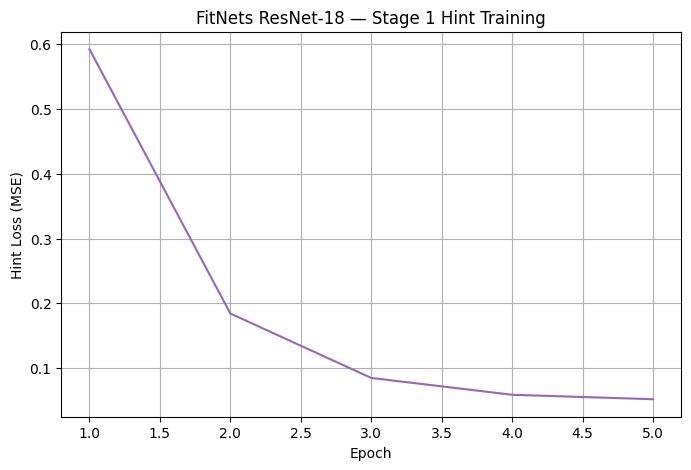

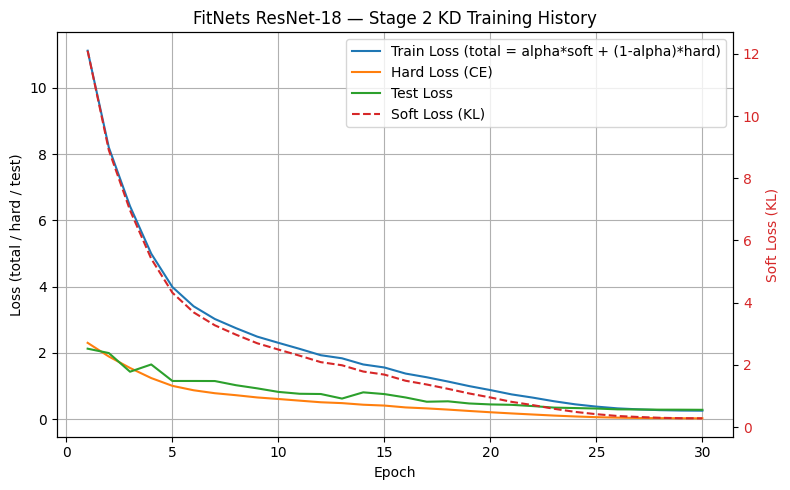

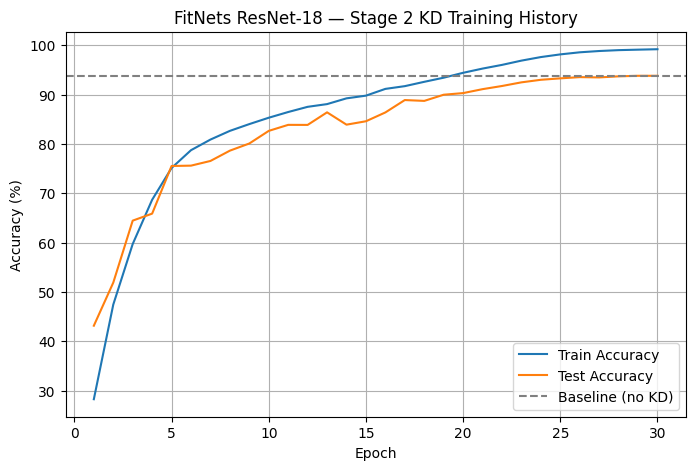

In [25]:
plot_hint_history(hint_history, "FitNets ResNet-18 — Stage 1 Hint Training")
plot_kd_history(kd_history, "FitNets ResNet-18 — Stage 2 KD Training History")